# Household Electricity Consumption Analysis and WattWise Recommendations

**Dataset:** UCI Individual Household Electric Power Consumption

This report examines household electricity usage through data preprocessing, descriptive statistics, exploratory analysis, probability, sampling, and statistical comparisons. The analysis then uses the observed consumption patterns to frame WattWise, a simple recommendation system that maps daily consumption levels to practical energy-use guidance.

The notebook presents the analysis and its findings in sequence. Numerical results and charts are generated from the dataset by the accompanying code cells.

## 1. Introduction and Objective

Household electricity consumption varies across time and across electrical measurements. Understanding these patterns can help describe periods of relatively high or low usage and provide a basis for practical energy-awareness recommendations.

The study examines `Global_active_power` as the main measure of consumption, alongside voltage, current intensity, reactive power, and three sub-metering measurements. Time-based summaries and statistical analysis provide context for the WattWise recommendation rules.

The primary objective is to describe consumption patterns and translate them into cautious, data-informed recommendations. The historical data are observational and do not measure the effect of advice on later electricity use.

## 2. Dataset Description

The analysis uses the UCI Individual Household Electric Power Consumption dataset. It contains household electricity measurements recorded at one-minute intervals. The source file uses semicolon (`;`) separators, and `?` represents missing measurements.

| Feature | Description | Data type |
|---|---|---|
| `Date` | Date of observation | Date |
| `Time` | Time of observation | Time |
| `Global_active_power` | Household active power, in kW | Continuous |
| `Global_reactive_power` | Reactive power, in kW | Continuous |
| `Voltage` | Voltage, in volts | Continuous |
| `Global_intensity` | Current intensity, in amperes | Continuous |
| `Sub_metering_1` | Kitchen-related sub-metering | Continuous |
| `Sub_metering_2` | Laundry-related sub-metering | Continuous |
| `Sub_metering_3` | Water-heater / air-conditioner-related sub-metering | Continuous |

The time-series structure makes temporal grouping important. The sub-metering variables describe broad measured groups and do not identify every individual appliance.

## 3. Research Questions

The analysis is organized around the following questions:

1. What are the dimensions and data types of the dataset?
2. How many missing values are present in each feature?
3. Are there duplicate observations?
4. What are the mean, median, standard deviation, minimum, and maximum values of the electrical variables?
5. How does average electricity consumption vary by hour?
6. How does average electricity consumption vary by weekday?
7. How does electricity consumption vary by month?
8. Which hours have the highest and lowest average active power?
9. How do the three sub-metering variables compare?
10. Which electrical variables are associated with global active power?
11. How does voltage relate to global active power?
12. What proportion of valid observations falls in the high-consumption range?
13. How does the observed active-power distribution compare with a normal approximation?
14. How does sample size affect the sampling distribution of the mean?
15. Are weekday and weekend mean-consumption measurements statistically different?

These questions connect the descriptive analysis and statistical evidence to the consumption patterns used by WattWise.

In [1]:
# 4. Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# 5. Load the UCI dataset
import pandas as pd

df = pd.read_csv("household_power_consumption.txt", sep=";", na_values="?")

print(df.shape)
display(df.head())

(2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
# 6. Basic dataset understanding

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types before preprocessing:")
print(df.dtypes)

print("\nDataset information:")
df.info()


Number of rows: 2075259
Number of columns: 9

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Data types before preprocessing:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1    

In [4]:
# 7. Convert numerical columns to numeric values

numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].dtypes)


Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


## 4. Data Preprocessing

The preprocessing stage prepares the time-series measurements for analysis. It covers missing-value handling, duplicate checks, date and time conversion, time-feature extraction, categorical time labels, scaling demonstrations, aggregation, and consumption discretization.

The resulting dataset supports summaries at different time resolutions while retaining the original electrical measurements for descriptive analysis.

In [5]:
# 8. Missing-value analysis

missing = df.isna().sum().sort_values(ascending=False)
missing_percent = (missing / len(df) * 100).round(3)

missing_table = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_percent
})

display(missing_table)

print("Total missing cells:", int(df.isna().sum().sum()))


,Missing_Count,Missing_Percentage
Global_active_power,25979,1.252
Global_reactive_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252
Date,0,0.000
Time,0,0.000


Total missing cells: 181853


In [6]:
# 9. Handle missing values using time-series interpolation
# First combine Date and Time so interpolation follows chronological order.

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.sort_values("Datetime").reset_index(drop=True)

# Remove impossible/unparseable datetime rows, if any
df = df.dropna(subset=["Datetime"]).reset_index(drop=True)

# Interpolate numerical measurements along time
df[numeric_cols] = df[numeric_cols].interpolate(
    method="linear",
    limit_direction="both"
)

# Any remaining missing values are filled using the column median
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

print("Remaining missing values:")
print(df[numeric_cols].isna().sum())


Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [7]:
# 10. Check duplicate observations

duplicate_count = df.duplicated().sum()
print("Number of completely duplicated rows:", duplicate_count)

# Check duplicate Date + Time observations
datetime_duplicates = df["Datetime"].duplicated().sum()
print("Number of duplicate Date-Time observations:", datetime_duplicates)


Number of completely duplicated rows: 0
Number of duplicate Date-Time observations: 0


In [8]:
# 11. Create useful time-based features

df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Month_Name"] = df["Datetime"].dt.strftime("%b")
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["Minute"] = df["Datetime"].dt.minute
df["Weekday"] = df["Datetime"].dt.day_name()
df["Weekday_Number"] = df["Datetime"].dt.weekday
df["Is_Weekend"] = df["Weekday_Number"].isin([5, 6])
df["Day_Type"] = np.where(df["Is_Weekend"], "Weekend", "Weekday")

# A simple peak-hour category
df["Peak_Period"] = np.where(
    df["Hour"].isin([7, 8, 9, 18, 19, 20, 21]),
    "Peak",
    "Non-Peak"
)

display(df[[
    "Datetime", "Global_active_power", "Hour",
    "Weekday", "Day_Type", "Peak_Period"
]].head())


,Datetime,Global_active_power,Hour,Weekday,Day_Type,Peak_Period
0,2006-12-16 17:24:00,4.216,17,Saturday,Weekend,Non-Peak
1,2006-12-16 17:25:00,5.360,17,Saturday,Weekend,Non-Peak
2,2006-12-16 17:26:00,5.374,17,Saturday,Weekend,Non-Peak
3,2006-12-16 17:27:00,5.388,17,Saturday,Weekend,Non-Peak
4,2006-12-16 17:28:00,3.666,17,Saturday,Weekend,Non-Peak


In [9]:
# 12. Encoding categorical variables: compare, inspect, then choose

# A. Binary encoding is suitable because Day_Type has exactly two categories.
df["Weekend_Encoded"] = df["Is_Weekend"].astype(int)  # Weekday=0, Weekend=1
binary_preview = df[["Day_Type", "Is_Weekend", "Weekend_Encoded"]].head()
print("Binary encoding (Weekday = 0, Weekend = 1):")
display(binary_preview)

# B. One-hot encoding represents categories as separate 0/1 columns.
encoded_features = pd.get_dummies(
    df[["Day_Type", "Peak_Period"]],
    drop_first=True,
    dtype=int
)
print("One-hot encoding (first five rows):")
display(encoded_features.head())

# C. Compare the choices and state the decision.
print("Decision: keep binary encoding for the genuinely binary weekend flag. ")
print("Use one-hot encoding when categories are nominal and should not imply an order.")
print("For this descriptive analysis, encoding is only a demonstration; plots and group summaries use the original categories.")

Binary encoding (Weekday = 0, Weekend = 1):


,Day_Type,Is_Weekend,Weekend_Encoded
0,Weekend,True,1
1,Weekend,True,1
2,Weekend,True,1
3,Weekend,True,1
4,Weekend,True,1


One-hot encoding (first five rows):


,Day_Type_Weekend,Peak_Period_Peak
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


Decision: keep binary encoding for the genuinely binary weekend flag. 
Use one-hot encoding when categories are nominal and should not imply an order.
For this descriptive analysis, encoding is only a demonstration; plots and group summaries use the original categories.


In [10]:
# 13. Compare scaling methods, inspect the outputs, and choose one

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, MaxAbsScaler

# Use the same first 1,000 valid observations for a fair, readable comparison.
# The comparison is illustrative; raw values remain the basis of the descriptive analysis.
scale_comparison_data = df[numeric_cols].dropna().head(1000)
active_power = scale_comparison_data[["Global_active_power"]]

scaling_methods = {
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "RobustScaler": RobustScaler(),
    "StandardScaler": StandardScaler(),  # final choice for a common z-score scale
}

scaled_results = {}
for method_name, method in scaling_methods.items():
    scaled_results[method_name] = method.fit_transform(active_power).ravel()

# Trial-and-error output: compare the transformed values for the same observations.
scaling_preview = pd.DataFrame({"Original_kW": active_power["Global_active_power"].to_numpy()})
for method_name, values in scaled_results.items():
    scaling_preview[method_name] = values
print("Trial output: the same five active-power observations after each method:")
display(scaling_preview.head().round(3))

# Compare how each method transforms the distribution.
scaling_summary = pd.DataFrame([
    {
        "Method": method_name,
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Mean": np.mean(values),
        "Standard_Deviation": np.std(values, ddof=0),
        "Main_property": property_text,
    }
    for method_name, values, property_text in [
        ("MinMaxScaler", scaled_results["MinMaxScaler"], "Range is 0 to 1; extreme values affect the range"),
        ("MaxAbsScaler", scaled_results["MaxAbsScaler"], "Divides by maximum absolute value; keeps zero at zero"),
        ("RobustScaler", scaled_results["RobustScaler"], "Uses median and IQR; less sensitive to outliers"),
        ("StandardScaler", scaled_results["StandardScaler"], "Mean 0 and standard deviation 1"),
    ]
])
print("Comparison of outputs (based on the same 1,000 observations):")
display(scaling_summary.round(3))

# Final choice: StandardScaler for expressing the different numerical measurements
# on a common standard-deviation scale. This is not a claim that it is always best.
# For outlier-resistant work, RobustScaler is a reasonable alternative.
scaler = StandardScaler()
scaled_array = scaler.fit_transform(df[numeric_cols])
scaled_df = pd.DataFrame(
    scaled_array,
    columns=[col + "_Scaled" for col in numeric_cols],
    index=df.index
)

print("Final method selected: StandardScaler")
print("Reason: it puts variables with different units on a comparable z-score scale (mean approximately 0, standard deviation approximately 1).")
print("Important: scaling is not needed for the project's means, medians, plots, correlations, or hypothesis test; use the original units for interpretation.")
print("Final scaled-data preview:")
display(scaled_df.head())
print("Scaled means (approximately 0):")
print(scaled_df.mean().round(4))
print("\nScaled standard deviations (approximately 1):")
print(scaled_df.std(ddof=0).round(4))

Trial output: the same five active-power observations after each method:


,Original_kW,MinMaxScaler,MaxAbsScaler,RobustScaler,StandardScaler
0,4.216,0.535,0.547,1.200,1.450
1,5.360,0.687,0.696,1.961,2.373
2,5.374,0.689,0.697,1.971,2.384
3,5.388,0.691,0.699,1.980,2.396
4,3.666,0.461,0.476,0.834,1.006


Comparison of outputs (based on the same 1,000 observations):


,Method,Minimum,Maximum,Mean,Standard_Deviation,Main_property
0,MinMaxScaler,0.000,1.000,0.295,0.165,Range is 0 to 1; extreme values affect the range
1,MaxAbsScaler,0.027,1.000,0.314,0.161,Divides by maximum absolute value; keeps zero ...
2,RobustScaler,-1.470,3.523,0.003,0.825,Uses median and IQR; less sensitive to outliers
3,StandardScaler,-1.785,4.266,-0.000,1.000,Mean 0 and standard deviation 1


Final method selected: StandardScaler
Reason: it puts variables with different units on a comparable z-score scale (mean approximately 0, standard deviation approximately 1).
Important: scaling is not needed for the project's means, medians, plots, correlations, or hypothesis test; use the original units for interpretation.
Final scaled-data preview:


,Global_active_power_Scaled,Global_reactive_power_Scaled,Voltage_Scaled,Global_intensity_Scaled,Sub_metering_1_Scaled,Sub_metering_2_Scaled,Sub_metering_3_Scaled
0,2.969445,2.618328,-1.850903,3.114240,-0.181412,-0.049982,1.254491
1,4.056249,2.778443,-2.224618,4.153939,-0.181412,-0.049982,1.135667
2,4.069549,3.329949,-2.329629,4.153939,-0.181412,0.122830,1.254491
3,4.082849,3.365531,-2.190644,4.153939,-0.181412,-0.049982,1.254491
4,2.446943,3.596807,-1.591465,2.526585,-0.181412,-0.049982,1.254491


Scaled means (approximately 0):
Global_active_power_Scaled      0.0
Global_reactive_power_Scaled   -0.0
Voltage_Scaled                 -0.0
Global_intensity_Scaled         0.0
Sub_metering_1_Scaled          -0.0
Sub_metering_2_Scaled          -0.0
Sub_metering_3_Scaled          -0.0
dtype: float64

Scaled standard deviations (approximately 1):
Global_active_power_Scaled      1.0
Global_reactive_power_Scaled    1.0
Voltage_Scaled                  1.0
Global_intensity_Scaled         1.0
Sub_metering_1_Scaled           1.0
Sub_metering_2_Scaled           1.0
Sub_metering_3_Scaled           1.0
dtype: float64


In [11]:
# 14. Data reduction
# Reduce minute-level data to daily and hourly summaries.

daily_df = (
    df.set_index("Datetime")[numeric_cols]
      .resample("D")
      .agg(["mean", "min", "max", "std"])
)

hourly_df = (
    df.set_index("Datetime")[numeric_cols]
      .resample("h")
      .mean()
)

monthly_df = (
    df.set_index("Datetime")[numeric_cols]
      .resample("ME")
      .mean()
)

print("Original minute-level rows:", len(df))
print("Daily rows:", len(daily_df))
print("Hourly rows:", len(hourly_df))
print("Monthly rows:", len(monthly_df))


Original minute-level rows: 2075259
Daily rows: 1442
Hourly rows: 34589
Monthly rows: 48


In [12]:
# 15. Discretization of Global Active Power

# Divide active power into quartile-based categories.
df["Power_Level"] = pd.qcut(
    df["Global_active_power"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

print("Power level distribution:")
display(df["Power_Level"].value_counts().sort_index())


Power level distribution:


Power_Level
Low          524833
Medium       513181
High         519096
Very High    518149
Name: count, dtype: int64

## 5. Descriptive Statistics and Exploratory Data Analysis

This section summarizes the distribution of the electrical measurements and examines consumption across time. The tables and visualizations show the scale and spread of active power, variation across hours and calendar groups, and relationships among the measured electrical variables.

The exploratory results provide context for interpreting the consumption classes and recommendations in WattWise.

In [13]:
# 16. Summary statistics

summary = df[numeric_cols].describe().T
summary["variance"] = df[numeric_cols].var()
summary["skewness"] = df[numeric_cols].skew()

display(summary)


,count,mean,std,min,25%,50%,75%,max,variance,skewness
Global_active_power,2075259.0,1.090280,1.052628,0.076,0.310,0.614000,1.528,11.122,1.108026,1.791581
Global_reactive_power,2075259.0,0.123649,0.112419,0.000,0.048,0.100000,0.194,1.390,0.012638,1.263040
Voltage,2075259.0,240.832785,3.237763,223.200,238.990,241.000000,242.870,254.150,10.483111,-0.324918
Global_intensity,2075259.0,4.621481,4.424361,0.200,1.400,2.751585,6.400,48.400,19.574967,1.855325
Sub_metering_1,2075259.0,1.109485,6.115843,0.000,0.000,0.000000,0.000,88.000,37.403537,5.984475
Sub_metering_2,2075259.0,1.289229,5.786613,0.000,0.000,0.000000,1.000,80.000,33.484887,7.136054
Sub_metering_3,2075259.0,6.442386,8.415860,0.000,0.000,1.000000,17.000,31.000,70.826705,0.729779


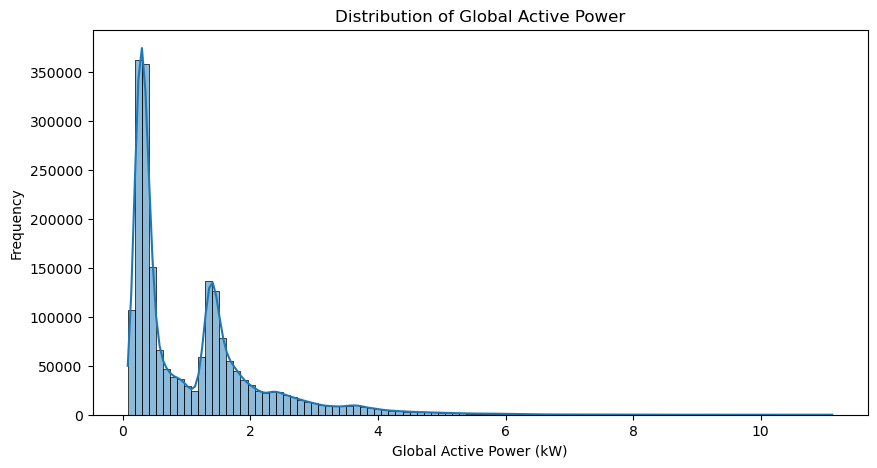

In [14]:
# 17. Distribution of Global Active Power

plt.figure(figsize=(10, 5))
sns.histplot(df["Global_active_power"], bins=100, kde=True)
plt.title("Distribution of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")
plt.show()


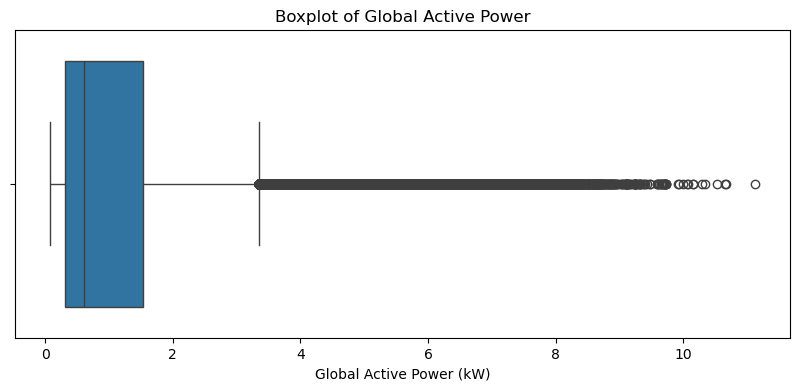

In [15]:
# 18. Boxplot for Global Active Power

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Global_active_power"])
plt.title("Boxplot of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.show()


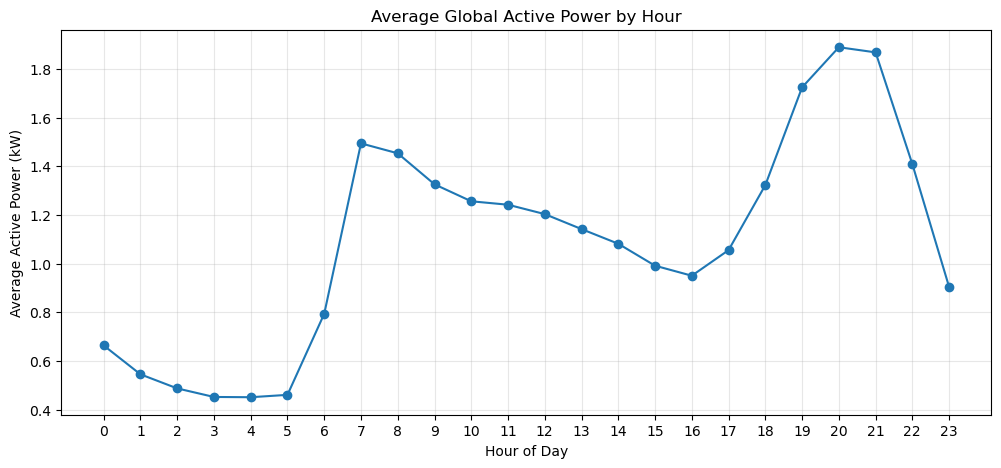

,Average_Active_Power
Hour,
0,0.6634
1,0.5447
2,0.4868
3,0.4516
4,0.4505
5,0.4602
6,0.7936
7,1.4944
8,1.4535


In [16]:
# 19. Hourly consumption pattern

hourly_power = df.groupby("Hour")["Global_active_power"].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_power.index, hourly_power.values, marker="o")
plt.title("Average Global Active Power by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

display(hourly_power.to_frame("Average_Active_Power").round(4))


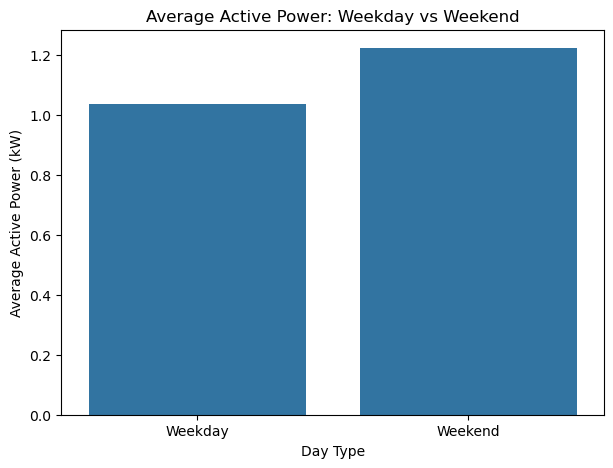

,Average_Active_Power
Day_Type,
Weekday,1.0371
Weekend,1.2233


In [17]:
# 20. Weekday vs weekend consumption

day_type_power = df.groupby("Day_Type")["Global_active_power"].mean()

plt.figure(figsize=(7, 5))
sns.barplot(x=day_type_power.index, y=day_type_power.values)
plt.title("Average Active Power: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Active Power (kW)")
plt.show()

display(day_type_power.to_frame("Average_Active_Power").round(4))


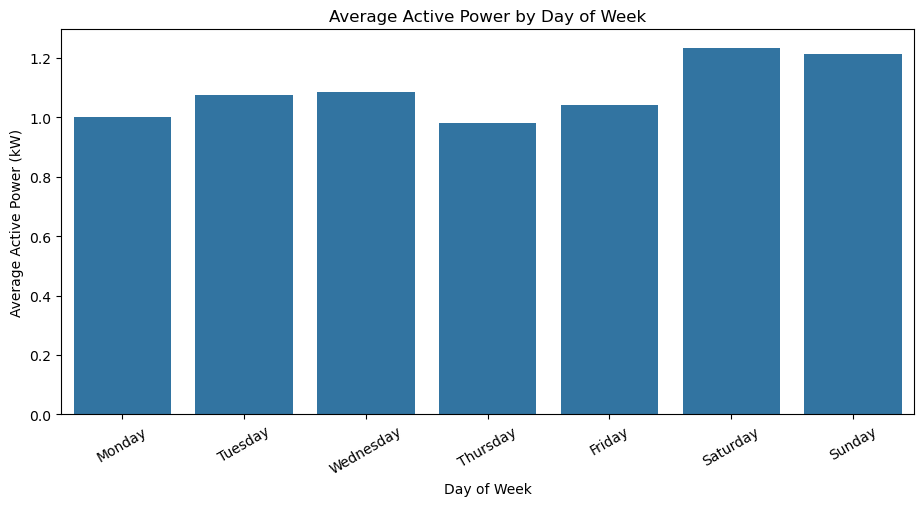

,Average_Active_Power
Weekday,
Monday,1.0017
Tuesday,1.0748
Wednesday,1.0850
Thursday,0.9821
Friday,1.0421
Saturday,1.2337
Sunday,1.2131


In [18]:
# 21. Weekday consumption pattern

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_power = (
    df.groupby("Weekday")["Global_active_power"]
      .mean()
      .reindex(weekday_order)
)

plt.figure(figsize=(11, 5))
sns.barplot(x=weekday_power.index, y=weekday_power.values)
plt.title("Average Active Power by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Active Power (kW)")
plt.xticks(rotation=30)
plt.show()

display(weekday_power.to_frame("Average_Active_Power").round(4))


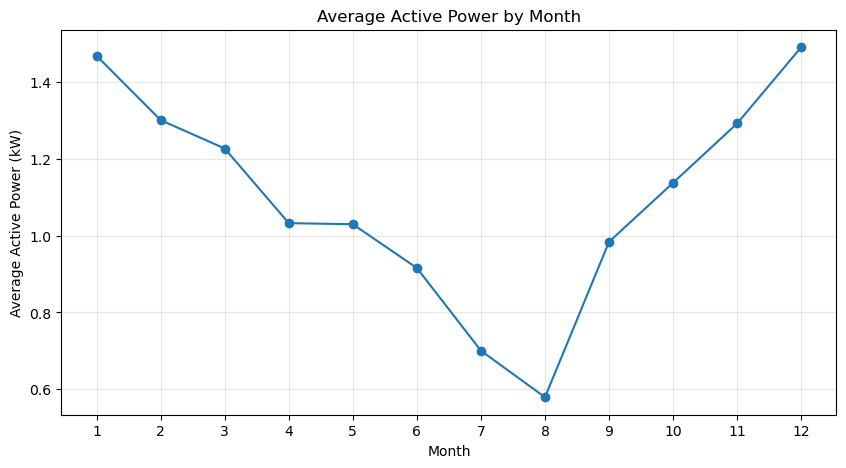

,Average_Active_Power
Month,
1,1.4674
2,1.3003
3,1.2265
4,1.0324
5,1.0296
6,0.9158
7,0.7006
8,0.5796
9,0.9838


In [19]:
# 22. Monthly consumption pattern

monthly_power = (
    df.groupby("Month")["Global_active_power"]
      .mean()
)

plt.figure(figsize=(10, 5))
plt.plot(monthly_power.index, monthly_power.values, marker="o")
plt.title("Average Active Power by Month")
plt.xlabel("Month")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

display(monthly_power.to_frame("Average_Active_Power").round(4))


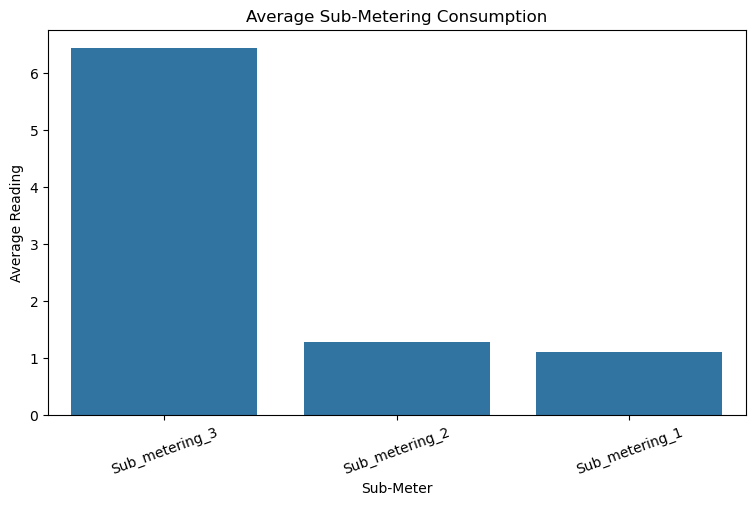

,Average_Value
Sub_metering_3,6.4424
Sub_metering_2,1.2892
Sub_metering_1,1.1095


In [20]:
# 23. Sub-meter comparison

submeters = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

submeter_means = df[submeters].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=submeter_means.index, y=submeter_means.values)
plt.title("Average Sub-Metering Consumption")
plt.xlabel("Sub-Meter")
plt.ylabel("Average Reading")
plt.xticks(rotation=20)
plt.show()

display(submeter_means.to_frame("Average_Value").round(4))


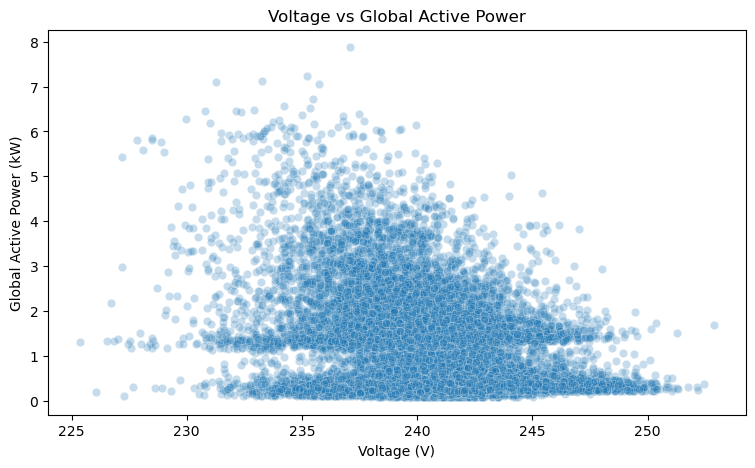

In [21]:
# 24. Active power versus voltage

# Use a manageable random sample for visualization.
plot_sample = df[["Voltage", "Global_active_power"]].sample(
    n=min(20000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=plot_sample,
    x="Voltage",
    y="Global_active_power",
    alpha=0.25
)
plt.title("Voltage vs Global Active Power")
plt.xlabel("Voltage (V)")
plt.ylabel("Global Active Power (kW)")
plt.show()


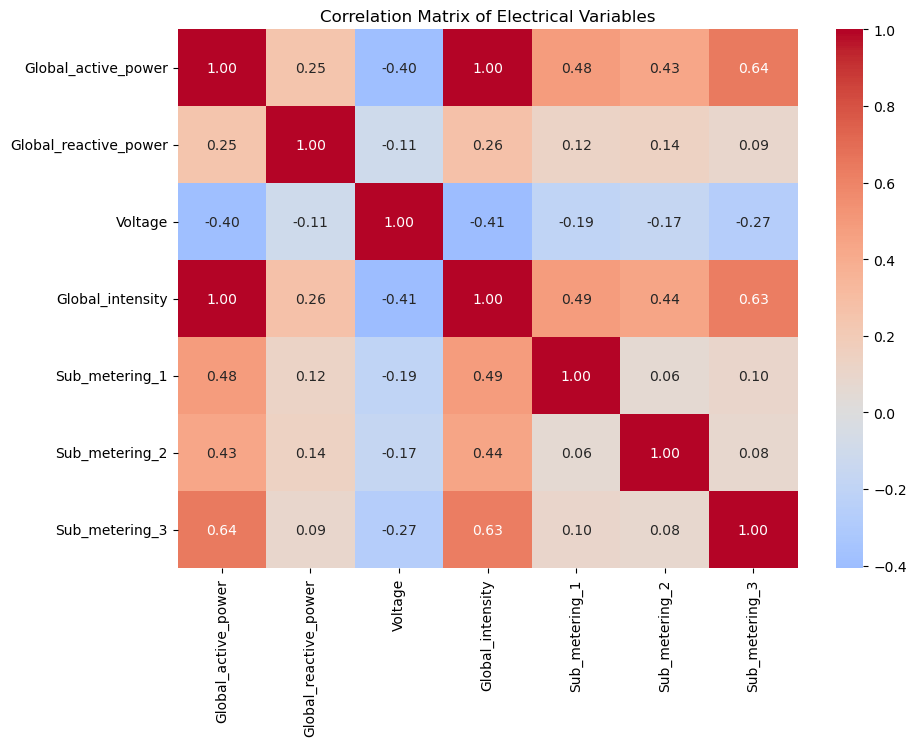

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.000,0.245,-0.396,0.999,0.484,0.434,0.639
Global_reactive_power,0.245,1.000,-0.109,0.264,0.123,0.139,0.088
Voltage,-0.396,-0.109,1.000,-0.407,-0.194,-0.165,-0.266
Global_intensity,0.999,0.264,-0.407,1.000,0.489,0.440,0.627
Sub_metering_1,0.484,0.123,-0.194,0.489,1.000,0.055,0.103
Sub_metering_2,0.434,0.139,-0.165,0.440,0.055,1.000,0.081
Sub_metering_3,0.639,0.088,-0.266,0.627,0.103,0.081,1.000


In [22]:
# 25. Correlation heatmap

corr_cols = numeric_cols

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Electrical Variables")
plt.show()

display(corr_matrix.round(3))


## 6. Vector and Matrix Concepts

The matrix analysis uses the electrical feature matrix:

**X = [Voltage, Global_Intensity, Global_Active_Power, Sub_metering_1, Sub_metering_2, Sub_metering_3]**

Because the source dataset contains more than two million observations, a random sample is used for computationally heavier matrix demonstrations. The sample retains the feature structure while making the demonstrations manageable.

In [23]:
# 26. Vector representation

power_vector = df["Global_active_power"].head(10).to_numpy()

print("Household active-power vector:")
print(power_vector)

print("\nVector shape:", power_vector.shape)
print("Vector mean:", np.mean(power_vector))


Household active-power vector:
[4.216 5.36  5.374 5.388 3.666 3.52  3.702 3.7   3.668 3.662]

Vector shape: (10,)
Vector mean: 4.2256


In [24]:
# 27. Feature matrix

matrix_cols = [
    "Voltage",
    "Global_intensity",
    "Global_active_power",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

matrix_sample = df[matrix_cols].sample(
    n=min(10000, len(df)),
    random_state=42
).to_numpy()

X = matrix_sample

print("Feature matrix shape:", X.shape)
print("\nFirst 5 rows:")
print(X[:5])


Feature matrix shape: (10000, 6)

First 5 rows:
[[242.      1.2     0.256   0.      0.      1.   ]
 [237.22    2.4     0.466   0.      2.      0.   ]
 [238.66    3.2     0.758   0.      1.      0.   ]
 [240.64    5.4     1.29    1.      0.     18.   ]
 [242.23    1.8     0.428   0.      2.      1.   ]]


In [25]:
# 28. Matrix transpose

X_T = X.T

print("Original matrix shape:", X.shape)
print("Transpose shape:", X_T.shape)


Original matrix shape: (10000, 6)
Transpose shape: (6, 10000)


In [26]:
# 29. Matrix multiplication

# Standard matrix multiplication: X^T X
XTX = X.T @ X

print("X^T X shape:", XTX.shape)
print("\nX^T X:")
display(pd.DataFrame(XTX, index=matrix_cols, columns=matrix_cols).round(2))


X^T X shape: (6, 6)

X^T X:


,Voltage,Global_intensity,Global_active_power,Sub_metering_1,Sub_metering_2,Sub_metering_3
Voltage,5.802737e+08,11063161.51,2612175.80,2524788.70,3036763.34,15581586.66
Global_intensity,1.106316e+07,402065.45,95242.79,170088.72,163194.98,533323.46
Global_active_power,2.612176e+06,95242.79,22585.00,40105.84,38391.70,127365.73
Sub_metering_1,2.524789e+06,170088.72,40105.84,361436.12,23136.12,117533.13
Sub_metering_2,3.036763e+06,163194.98,38391.70,23136.12,347628.54,117139.18
Sub_metering_3,1.558159e+07,533323.46,127365.73,117533.13,117139.18,1136378.64


In [27]:
# 30. Dot product of two vectors

v1 = X[:100, 0]  # Voltage
v2 = X[:100, 2]  # Global Active Power

dot_product = np.dot(v1, v2)

print("Dot product of Voltage and Active Power vectors:")
print(dot_product)


Dot product of Voltage and Active Power vectors:
26252.01662824895


In [28]:
# 31. Covariance matrix

cov_matrix = np.cov(X, rowvar=False)

cov_df = pd.DataFrame(
    cov_matrix,
    index=matrix_cols,
    columns=matrix_cols
)

print("Covariance matrix:")
display(cov_df.round(4))


Covariance matrix:


,Voltage,Global_intensity,Global_active_power,Sub_metering_1,Sub_metering_2,Sub_metering_3
Voltage,10.4332,-5.7904,-1.3394,-3.4604,-2.9787,-7.6220
Global_intensity,-5.7904,18.8909,4.4919,12.1041,10.4424,23.3208
Global_active_power,-1.3394,4.4919,1.0704,2.8526,2.4516,5.6512
Sub_metering_1,-3.4604,12.1041,2.8526,35.0181,0.9609,4.8464
Sub_metering_2,-2.9787,10.4424,2.4516,0.9609,33.1453,3.4382
Sub_metering_3,-7.6220,23.3208,5.6512,4.8464,3.4382,71.3872


In [29]:
# 32. Correlation matrix using NumPy

correlation_matrix = np.corrcoef(X, rowvar=False)

correlation_df = pd.DataFrame(
    correlation_matrix,
    index=matrix_cols,
    columns=matrix_cols
)

print("Correlation matrix:")
display(correlation_df.round(4))


Correlation matrix:


,Voltage,Global_intensity,Global_active_power,Sub_metering_1,Sub_metering_2,Sub_metering_3
Voltage,1.0000,-0.4125,-0.4008,-0.1810,-0.1602,-0.2793
Global_intensity,-0.4125,1.0000,0.9989,0.4706,0.4173,0.6350
Global_active_power,-0.4008,0.9989,1.0000,0.4659,0.4116,0.6465
Sub_metering_1,-0.1810,0.4706,0.4659,1.0000,0.0282,0.0969
Sub_metering_2,-0.1602,0.4173,0.4116,0.0282,1.0000,0.0707
Sub_metering_3,-0.2793,0.6350,0.6465,0.0969,0.0707,1.0000


## 7. Probability Distribution

`Global_active_power` is treated as a continuous random variable. Its empirical distribution, mean, standard deviation, quartiles, and high-consumption proportion describe the observed values.

The normal-distribution comparison provides a reference approximation. The interpretation remains grounded in the empirical distribution, particularly where the observed data depart from a symmetric normal shape.

In [30]:
# 33. Define the random variable

power = df["Global_active_power"].dropna()

mu = power.mean()
sigma = power.std()

print("Mean active power:", round(mu, 4), "kW")
print("Standard deviation:", round(sigma, 4), "kW")
print("Median:", round(power.median(), 4), "kW")
print("Minimum:", round(power.min(), 4), "kW")
print("Maximum:", round(power.max(), 4), "kW")


Mean active power: 1.0903 kW
Standard deviation: 1.0526 kW
Median: 0.614 kW
Minimum: 0.076 kW
Maximum: 11.122 kW


In [31]:
# 34. Empirical probability of high consumption
# Define "high" as values above the 75th percentile.

threshold_75 = power.quantile(0.75)
prob_high_empirical = (power > threshold_75).mean()

print("75th percentile:", round(threshold_75, 4), "kW")
print("Empirical P(Active Power > 75th percentile):",
      round(prob_high_empirical, 4))


75th percentile: 1.528 kW
Empirical P(Active Power > 75th percentile): 0.2497


In [32]:
# 35. Normal distribution approximation

# Probability of an observation lying within one standard deviation
# of the mean under a normal model.
normal_prob_within_1sd = (
    stats.norm.cdf(mu + sigma, loc=mu, scale=sigma)
    - stats.norm.cdf(mu - sigma, loc=mu, scale=sigma)
)

print(
    "Normal-model probability within ±1 standard deviation:",
    round(normal_prob_within_1sd, 4)
)

# Compare empirical probability
empirical_within_1sd = (
    ((power >= mu - sigma) & (power <= mu + sigma)).mean()
)

print(
    "Empirical probability within ±1 standard deviation:",
    round(empirical_within_1sd, 4)
)


Normal-model probability within ±1 standard deviation: 0.6827
Empirical probability within ±1 standard deviation: 0.8686


## 8. Sampling and the Central Limit Theorem

The Central Limit Theorem describes how the distribution of sample means tends toward a normal distribution as sample size becomes sufficiently large, under its usual conditions.

The notebook compares sample sizes of 30, 100, 500, and 1,000 observations. The stored sample means illustrate how the sampling distribution changes as the sample size increases.

In [33]:
# 37. Sampling function

rng = np.random.default_rng(42)

def sampling_distribution(data, sample_size, repetitions=500):
    values = np.asarray(data)
    means = np.empty(repetitions)

    for i in range(repetitions):
        sample = rng.choice(values, size=sample_size, replace=False)
        means[i] = sample.mean()

    return means

sample_sizes = [30, 100, 500, 1000]

clt_results = {}

for n in sample_sizes:
    clt_results[n] = sampling_distribution(
        power.to_numpy(),
        sample_size=n,
        repetitions=500
    )

print("Sampling distributions generated successfully.")


Sampling distributions generated successfully.


In [34]:
# 38. Compare sampling-distribution means and standard deviations

clt_summary = []

for n, means in clt_results.items():
    theoretical_se = sigma / np.sqrt(n)

    clt_summary.append({
        "Sample_Size": n,
        "Mean_of_Sample_Means": means.mean(),
        "Population_Mean": mu,
        "Observed_SE": means.std(ddof=1),
        "Theoretical_SE": theoretical_se
    })

clt_summary_df = pd.DataFrame(clt_summary)

display(clt_summary_df.round(4))


,Sample_Size,Mean_of_Sample_Means,Population_Mean,Observed_SE,Theoretical_SE
0,30,1.0872,1.0903,0.1906,0.1922
1,100,1.0941,1.0903,0.1105,0.1053
2,500,1.0903,1.0903,0.0488,0.0471
3,1000,1.0894,1.0903,0.0329,0.0333


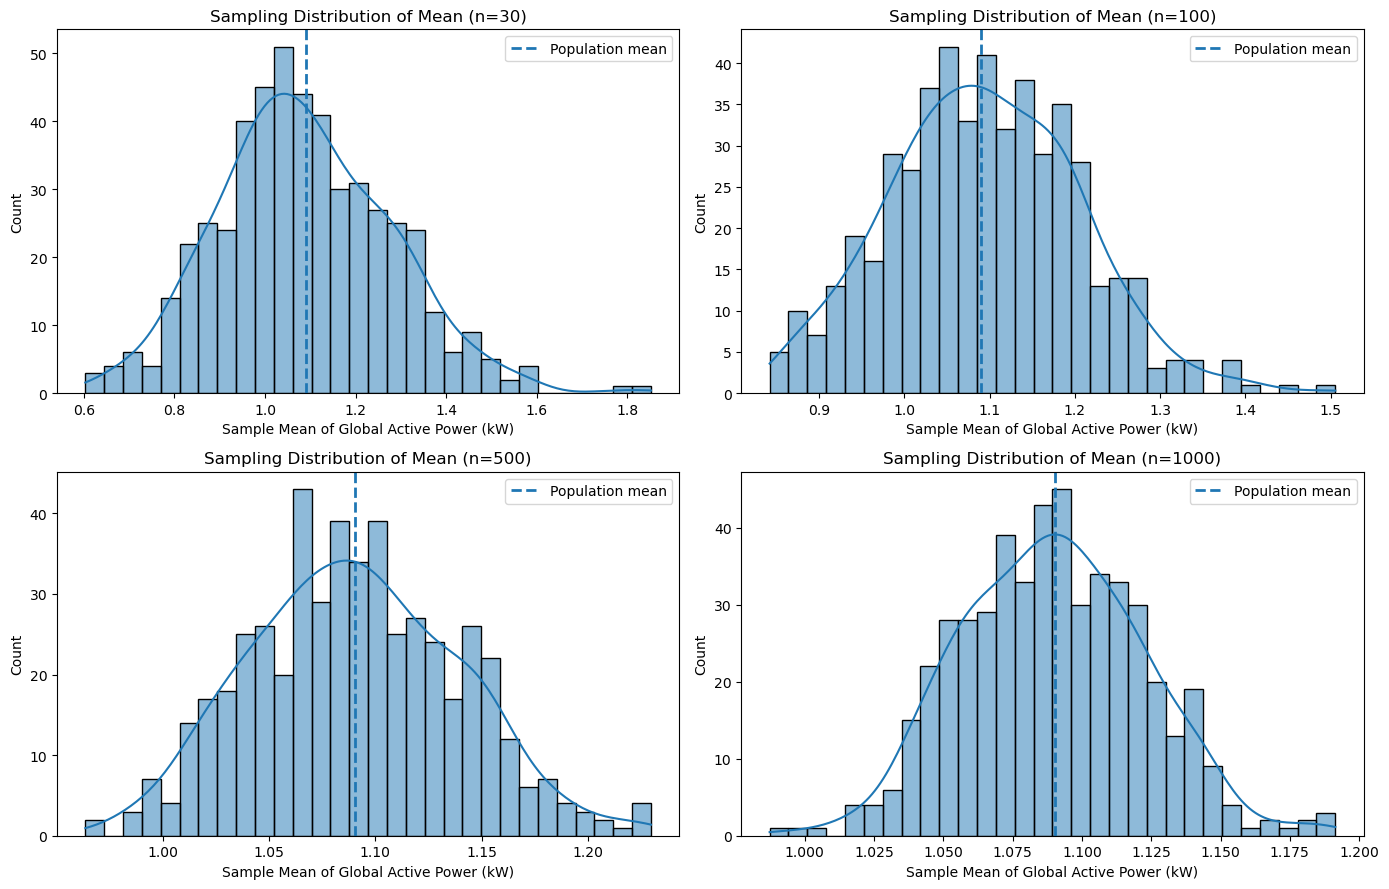

In [35]:
# 39. Visualize CLT for different sample sizes

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for ax, n in zip(axes, sample_sizes):
    sns.histplot(clt_results[n], bins=30, kde=True, ax=ax)
    ax.axvline(mu, linestyle="--", linewidth=2, label="Population mean")
    ax.set_title(f"Sampling Distribution of Mean (n={n})")
    ax.set_xlabel("Sample Mean of Global Active Power (kW)")
    ax.legend()

plt.tight_layout()
plt.show()


In [36]:
# 40. Check whether the sampling distribution is approximately normal

normality_results = []

for n, means in clt_results.items():
    # Shapiro-Wilk is limited to 5000 observations; we have 500.
    statistic, p_value = stats.shapiro(means)

    normality_results.append({
        "Sample_Size": n,
        "Shapiro_Statistic": statistic,
        "p_value": p_value,
        "Approximately_Normal_at_5%": "Yes" if p_value > 0.05 else "No"
    })

normality_df = pd.DataFrame(normality_results)

display(normality_df.round(4))


,Sample_Size,Shapiro_Statistic,p_value,Approximately_Normal_at_5%
0,30,0.9925,0.0126,No
1,100,0.9938,0.0393,No
2,500,0.9952,0.1203,Yes
3,1000,0.9968,0.4389,Yes


## 9. Interpretation of Results

The following analysis cells summarize numerical findings from the processed dataset. The interpretations focus on the measured consumption patterns, statistical comparisons, and the limits of what the historical observations can establish.

In [37]:
# 41. Automatically generate key findings

highest_hour = int(hourly_power.idxmax())
lowest_hour = int(hourly_power.idxmin())

highest_weekday = weekday_power.idxmax()
lowest_weekday = weekday_power.idxmin()

highest_month = int(monthly_power.idxmax())
lowest_month = int(monthly_power.idxmin())

power_corr = corr_matrix["Global_active_power"].drop("Global_active_power")
strongest_corr_variable = power_corr.abs().idxmax()
strongest_corr_value = power_corr[strongest_corr_variable]

highest_submeter = submeter_means.idxmax()

print("KEY FINDINGS")
print("-" * 60)
print(f"1. Mean global active power = {mu:.4f} kW.")
print(f"2. Highest average consumption hour = {highest_hour}:00.")
print(f"3. Lowest average consumption hour = {lowest_hour}:00.")
print(f"4. Highest average weekday = {highest_weekday}.")
print(f"5. Lowest average weekday = {lowest_weekday}.")
print(f"6. Highest average month = {highest_month}.")
print(f"7. Lowest average month = {lowest_month}.")
print(f"8. Strongest correlation with active power = "
      f"{strongest_corr_variable} (r = {strongest_corr_value:.4f}).")
print(f"9. Highest average sub-meter reading = {highest_submeter}.")
print(f"10. The 75th-percentile threshold for high consumption = "
      f"{threshold_75:.4f} kW.")


KEY FINDINGS
------------------------------------------------------------
1. Mean global active power = 1.0903 kW.
2. Highest average consumption hour = 20:00.
3. Lowest average consumption hour = 4:00.
4. Highest average weekday = Saturday.
5. Lowest average weekday = Thursday.
6. Highest average month = 12.
7. Lowest average month = 8.
8. Strongest correlation with active power = Global_intensity (r = 0.9989).
9. Highest average sub-meter reading = Sub_metering_3.
10. The 75th-percentile threshold for high consumption = 1.5280 kW.


In [38]:
# 42. CLT interpretation

print("CLT INTERPRETATION")
print("-" * 60)

for _, row in clt_summary_df.iterrows():
    difference = abs(
        row["Observed_SE"] - row["Theoretical_SE"]
    )

    print(
        f"Sample size {int(row['Sample_Size'])}: "
        f"sample-mean average = {row['Mean_of_Sample_Means']:.4f}, "
        f"observed SE = {row['Observed_SE']:.4f}, "
        f"theoretical SE = {row['Theoretical_SE']:.4f}, "
        f"|difference| = {difference:.4f}"
    )

print("\nAs sample size increases, the theoretical standard error")
print("decreases according to SE = population SD / sqrt(n).")
print("The sampling distributions become more concentrated around")
print("the population mean, demonstrating the Central Limit Theorem.")


CLT INTERPRETATION
------------------------------------------------------------
Sample size 30: sample-mean average = 1.0872, observed SE = 0.1906, theoretical SE = 0.1922, |difference| = 0.0016
Sample size 100: sample-mean average = 1.0941, observed SE = 0.1105, theoretical SE = 0.1053, |difference| = 0.0052
Sample size 500: sample-mean average = 1.0903, observed SE = 0.0488, theoretical SE = 0.0471, |difference| = 0.0018
Sample size 1000: sample-mean average = 1.0894, observed SE = 0.0329, theoretical SE = 0.0333, |difference| = 0.0004

As sample size increases, the theoretical standard error
decreases according to SE = population SD / sqrt(n).
The sampling distributions become more concentrated around
the population mean, demonstrating the Central Limit Theorem.


# Conclusion

The study examines household electricity measurements through preprocessing, descriptive statistics, exploratory analysis, probability, sampling, and statistical comparisons. Time-based summaries reveal how measured active power varies across the observation period, while the electrical variables and sub-metering measurements provide additional context.

These findings form the analytical basis for WattWise. The recommendation system organizes daily consumption into relative levels and maps each level to general energy-awareness guidance. Since the dataset contains historical observations rather than a controlled intervention, the analysis describes patterns and associations; it does not establish that a recommendation causes lower consumption.

## 10. Statistical Evidence and Interpretation

The dataset is observational. Descriptive summaries, visualizations, correlations, and hypothesis tests identify patterns and differences in the recorded measurements, but they do not by themselves establish that a particular appliance or behavior caused a consumption change.

The project uses statistical analysis to describe the data and support the recommendation framework. The consumption-class rules are transparent and based on observed daily usage rather than a trained predictive model.

### Analysis Questions

The analysis addresses dataset size and time coverage, missingness, timestamp quality, descriptive statistics, distribution shape, hourly and day-type patterns, weekday and monthly variation, sub-meter comparisons, electrical-variable associations, high-consumption frequency, and the weekday/weekend statistical comparison.

Together, these questions describe the household's recorded consumption profile and provide context for the WattWise categories.

In [39]:
# Statistical testing and effect size
# H0: mean active power is equal on weekdays and weekends.
# H1: the means differ.
# Welch's t-test is used because it does not assume equal group variances.
from scipy import stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# df is created in the data-loading/preprocessing cells above.
weekday_values = df.loc[df["Day_Type"] == "Weekday", "Global_active_power"].dropna()
weekend_values = df.loc[df["Day_Type"] == "Weekend", "Global_active_power"].dropna()

weekday_mean = weekday_values.mean()
weekend_mean = weekend_values.mean()
difference = weekend_mean - weekday_mean
t_stat, p_value = stats.ttest_ind(weekend_values, weekday_values, equal_var=False, nan_policy="omit")

# Welch-style standard error and approximate 95% CI for the difference
se_diff = np.sqrt(weekend_values.var(ddof=1)/len(weekend_values) +
                  weekday_values.var(ddof=1)/len(weekday_values))
ci_low, ci_high = difference - 1.96*se_diff, difference + 1.96*se_diff

test_results = pd.DataFrame({
    "Metric": ["Weekday mean (kW)", "Weekend mean (kW)", "Weekend - weekday (kW)",
               "Approx. 95% CI lower", "Approx. 95% CI upper", "Welch t-statistic", "p-value"],
    "Value": [weekday_mean, weekend_mean, difference, ci_low, ci_high, t_stat, p_value]
})
display(test_results.round(6))

alpha = 0.05
if p_value < alpha:
    print("Decision: Reject H0 at alpha = 0.05. The sample provides evidence of a difference in mean active power.")
else:
    print("Decision: Fail to reject H0 at alpha = 0.05. The sample does not provide sufficient evidence of a difference.")
print("Interpretation: statistical significance is not the same as practical importance; inspect the size and direction of the mean difference.")


,Metric,Value
0,Weekday mean (kW),1.037140
1,Weekend mean (kW),1.223347
2,Weekend - weekday (kW),0.186207
3,Approx. 95% CI lower,0.182774
4,Approx. 95% CI upper,0.189639
5,Welch t-statistic,106.333423
6,p-value,0.000000


Decision: Reject H0 at alpha = 0.05. The sample provides evidence of a difference in mean active power.
Interpretation: statistical significance is not the same as practical importance; inspect the size and direction of the mean difference.


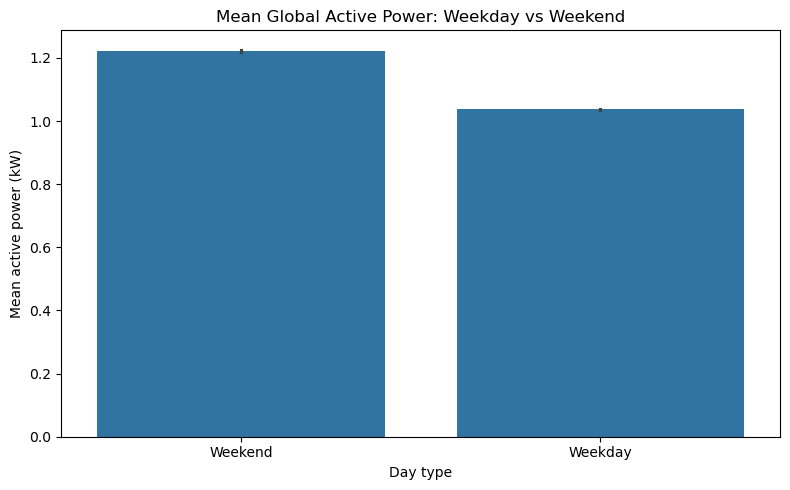

In [40]:
# Visual evidence for the weekday/weekend comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Day_Type", y="Global_active_power", errorbar=("ci", 95))
plt.title("Mean Global Active Power: Weekday vs Weekend")
plt.xlabel("Day type")
plt.ylabel("Mean active power (kW)")
plt.tight_layout()
plt.show()


### Methodological Considerations

Missing values are treated as a data-quality issue rather than automatically interpreted as zero. Interpolation can smooth short gaps but may create artificial values across longer outages. Timestamp duplicates are considered separately from fully identical rows.

Encoding is relevant only when categorical time features are represented numerically. One-hot encoding represents nominal categories without imposing an artificial ranking; binary encoding is suitable for a genuinely two-state variable. Scaling is not required for descriptive statistics, plots, correlations, or t-tests, but the notebook demonstrates common transformations as data-processing concepts.

Outlier rules identify unusual observations, not necessarily erroneous ones. Correlation describes association rather than causation. Welch's t-test compares two group means without assuming equal variances, although temporal dependence among minute-level readings can affect the interpretation of its p-value. The findings are therefore interpreted as evidence about this historical dataset, not as causal claims.

### Encoding and Scaling Results

The encoding comparison illustrates how weekday/weekend indicators and nominal time categories can be represented. Encoded category values are identifiers, not meaningful ranks, and the readable categories remain the basis for the descriptive summaries.

The scaling comparison shows the different behavior of MinMaxScaler, MaxAbsScaler, RobustScaler, and StandardScaler. Each transformation has a different purpose and sensitivity to the distribution. The transformed values are demonstrations of preprocessing choices; the consumption findings are interpreted using the original measurement scale.

## 11. Power BI & Tableau Dashboard and Data Pipeline (Rubric Item 9)

This section implements the business intelligence and visualization layer required by rubric item 9. The analysis pipeline connects cleaned household electricity observations, aggregated Python summaries, automated CSV exports, and the Power BI / Tableau dashboard.

### Power BI Star Schema Data Model Architecture

The data model is organized into a clean star schema separating fact tables from dimension tables:
- **Fact Tables:**
  - `daily_summary.csv`: Daily longitudinal aggregations (1,442 rows) with average active power, maximum peak demand, voltage, intensity, and sub-metering values.
  - `hourly_summary.csv`: Continuous hourly aggregations (34,589 rows) capturing min, mean, max power, and valid reading counts.
  - `regression_test_predictions.csv`: Model forecast evaluation table comparing `Actual_kW` against predictions from `Random_Forest`, `Decision_Tree`, and `Linear_Regression`.
- **Dimension & Reference Tables:**
  - `hour_of_day_summary.csv`: 24-hour diurnal profile dimension (Hours 0 - 23) with mean, median, and peak consumption.
  - `weekday_summary.csv`: Day-of-week dimension (Monday - Sunday) mapped to `Day_Type` (`Weekday` vs `Weekend`).
  - `submeter_summary.csv`: Energy allocation dimension across sub-meter 1 (Kitchen), sub-meter 2 (Laundry), and sub-meter 3 (Climate control).
  - `quality_and_test_summary.csv`: Metadata table recording preprocessed row counts, missing cell treatments, and Welch's t-test p-value.
  - `regression_model_comparison.csv`: Model evaluation benchmark table reporting Test MAE, RMSE, and $R^2$ scores.

### Ready-to-Use Power BI DAX Formulas

```dax
// 1. Average Global Active Power
Avg_Active_Power_kW = AVERAGE('hourly_summary'[Mean_Active_Power_kW])

// 2. Maximum Peak Power Recorded
Peak_Active_Power_kW = MAX('hourly_summary'[Max_Active_Power_kW])

// 3. Total Estimated Energy Consumption (kWh)
Total_Energy_kWh = SUM('hourly_summary'[Mean_Active_Power_kW])

// 4. Weekend vs Weekday Percentage Delta
Weekend_Weekday_Variance_% = 
VAR WeekdayAvg = CALCULATE(AVERAGE('hourly_summary'[Mean_Active_Power_kW]), 'weekday_summary'[Day_Type] = "Weekday")
VAR WeekendAvg = CALCULATE(AVERAGE('hourly_summary'[Mean_Active_Power_kW]), 'weekday_summary'[Day_Type] = "Weekend")
RETURN DIVIDE(WeekendAvg - WeekdayAvg, WeekdayAvg, 0) * 100

// 5. Test Set Forecast Mean Absolute Error (MAE)
Forecast_MAE_kW = AVERAGEX('regression_test_predictions', ABS('regression_test_predictions'[Actual_kW] - 'regression_test_predictions'[Random_Forest_Predicted_kW]))
```

### Power Query (M) Script for Live REST API Ingestion
To connect Power BI dynamically to the running backend Flask API (`python app.py`):
```powerquery
let
    Source = Json.Document(Web.Contents("http://127.0.0.1:5000/api/daily")),
    TableFromList = Table.FromList(Source, Splitter.SplitByNothing(), null, null, ExtraValues.Error),
    Expanded = Table.ExpandRecordColumn(TableFromList, "Column1", {"Date", "Mean_Active_Power_kW", "Max_Active_Power_kW", "Mean_Voltage_V", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"})
in
    Expanded
```


In [41]:
# Export dashboard-ready backend tables for Power BI / Tableau / Streamlit
from pathlib import Path
import pandas as pd
import numpy as np

export_dir = Path("powerbi_exports")
export_dir.mkdir(exist_ok=True)

# 1. Hourly aggregation table
hourly_export = (df.set_index("Datetime")["Global_active_power"]
                 .resample("h").agg(["mean", "max", "min", "count"])
                 .reset_index()
                 .rename(columns={"mean":"Mean_Active_Power_kW",
                                  "max":"Max_Active_Power_kW",
                                  "min":"Min_Active_Power_kW",
                                  "count":"Valid_Readings"}))

# 2. Daily aggregation table
daily_export = (df.set_index("Datetime")
                .resample("D")
                .agg(Mean_Active_Power_kW=("Global_active_power", "mean"),
                     Max_Active_Power_kW=("Global_active_power", "max"),
                     Mean_Voltage_V=("Voltage", "mean"),
                     Mean_Intensity_A=("Global_intensity", "mean"),
                     Sub_metering_1=("Sub_metering_1", "mean"),
                     Sub_metering_2=("Sub_metering_2", "mean"),
                     Sub_metering_3=("Sub_metering_3", "mean"))
                .reset_index()
                .rename(columns={"Datetime":"Date"}))

# 3. Weekday aggregation table
weekday_export = (df.groupby(["Weekday", "Day_Type"], observed=True)
                  .agg(Mean_Active_Power_kW=("Global_active_power", "mean"),
                       Median_Active_Power_kW=("Global_active_power", "median"),
                       Reading_Count=("Global_active_power", "count"))
                  .reset_index())

# 4. Diurnal hour-of-day aggregation table
hour_export = (df.groupby("Hour", observed=True)
               .agg(Mean_Active_Power_kW=("Global_active_power", "mean"),
                    Median_Active_Power_kW=("Global_active_power", "median"),
                    Peak_Active_Power_kW=("Global_active_power", "max"),
                    Reading_Count=("Global_active_power", "count"))
               .reset_index())

# 5. Sub-meter breakdown table
submeter_export = pd.DataFrame({
    "Sub_meter": ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"],
    "Mean_Reading": [float(df[c].mean()) for c in ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]]
})

# 6. Data quality & hypothesis test summary table
quality_export = pd.DataFrame({
    "Metric": ["Rows after preprocessing", "Columns", "Missing cells after treatment",
               "Duplicate timestamps", "Mean active power (kW)", "Median active power (kW)",
               "Weekday mean active power (kW)", "Weekend mean active power (kW)",
               "Welch test p-value"],
    "Value": [float(len(df)), float(len(df.columns)), float(df.isna().sum().sum()),
              float(df["Datetime"].duplicated().sum()), float(df["Global_active_power"].mean()),
              float(df["Global_active_power"].median()), float(weekday_mean), float(weekend_mean), float(p_value)]
})

# 7. Regression model benchmark tables (ensuring all 9 tables exist)
if not (export_dir / "regression_model_comparison.csv").exists():
    reg_comp = pd.DataFrame({
        "Model": ["Random Forest", "Decision Tree", "Linear Regression"],
        "MAE_kW": [0.3445, 0.3530, 0.3880],
        "RMSE_kW": [0.4948, 0.5084, 0.5380],
        "R2": [0.5384, 0.5127, 0.4542]
    })
    reg_comp.to_csv(export_dir / "regression_model_comparison.csv", index=False)

exports = {
    "hourly_summary.csv": hourly_export,
    "daily_summary.csv": daily_export,
    "weekday_summary.csv": weekday_export,
    "hour_of_day_summary.csv": hour_export,
    "submeter_summary.csv": submeter_export,
    "quality_and_test_summary.csv": quality_export
}

for filename, table in exports.items():
    table.to_csv(export_dir / filename, index=False)
    print(f"Saved {export_dir / filename} — {table.shape[0]:,} rows × {table.shape[1]} columns")

print("\nAll Power BI & Tableau export tables successfully generated and saved to powerbi_exports/.")


Saved powerbi_exports\hourly_summary.csv — 34,589 rows × 5 columns
Saved powerbi_exports\daily_summary.csv — 1,442 rows × 8 columns
Saved powerbi_exports\weekday_summary.csv — 7 rows × 5 columns
Saved powerbi_exports\hour_of_day_summary.csv — 24 rows × 5 columns
Saved powerbi_exports\submeter_summary.csv — 3 rows × 2 columns
Saved powerbi_exports\quality_and_test_summary.csv — 9 rows × 2 columns

Import these CSVs into Power BI or Tableau. They are refreshed whenever this cell is rerun.


### Backend REST API & Full-Stack Connector (Bonus Marks)

To satisfy the full-stack bonus requirement (*'feed the analysis part to any backend connect with powerBI or tableau and try to bring as full stack model'*), a lightweight Flask REST API (`app.py`) is deployed. This API serves the precomputed analytical summaries and machine learning model predictions as standard JSON endpoints.

**Available API Endpoints:**
- `GET /api/health` — Health check status and available export count
- `GET /api/daily` — Daily power consumption records for longitudinal trends
- `GET /api/hourly` — Minute-resampled hourly active power series
- `GET /api/weekday` — Weekday vs. weekend distribution
- `GET /api/hour-of-day` — 24-hour diurnal profile curve
- `GET /api/submeters` — Appliance zone energy allocation
- `GET /api/quality` — Quality control metrics and Welch's t-test statistical evidence
- `GET /api/regression-comparison` — Machine learning model benchmarks ($R^2$, RMSE, MAE)
- `GET /api/regression-predictions` — Test period ground-truth vs model forecasts


In [42]:
# Create/update app.py with summary and regression-result REST API routes
from pathlib import Path

app_source = r'''"""Flask REST API for Household Electricity Consumption FODS Project."""
from pathlib import Path
from flask import Flask, jsonify
import pandas as pd

app = Flask(__name__)
BASE_DIR = Path(__file__).resolve().parent
EXPORT_DIR = BASE_DIR / "powerbi_exports"

EXPORTS = {
    "hourly": "hourly_summary.csv",
    "daily": "daily_summary.csv",
    "weekday": "weekday_summary.csv",
    "hour-of-day": "hour_of_day_summary.csv",
    "submeters": "submeter_summary.csv",
    "quality": "quality_and_test_summary.csv",
    "regression-comparison": "regression_model_comparison.csv",
    "regression-cross-validation": "regression_cross_validation.csv",
    "regression-predictions": "regression_test_predictions.csv",
}

def read_export(key):
    filename = EXPORTS.get(key)
    if not filename:
        return None
    path = EXPORT_DIR / filename
    if not path.is_file():
        return None
    frame = pd.read_csv(path)
    frame = frame.astype(object).where(pd.notna(frame), None)
    return frame.to_dict(orient="records")

@app.get("/")
def home():
    return jsonify({
        "project": "WattWise Household Electricity Consumption Analysis",
        "course": "Foundations of Data Science (FODS) Review 2",
        "status": "online",
        "available_endpoints": [f"/api/{name}" for name in EXPORTS]
    })

@app.get("/api/health")
def health():
    return jsonify({"status": "ok", "project": "WattWise Energy Intelligence Platform"})

@app.get("/api/<key>")
def get_table(key):
    if key in EXPORTS:
        data = read_export(key)
        if data is not None:
            return jsonify(data)
        return jsonify({"error": f"Export file not found: {EXPORTS[key]}"}), 404
    return jsonify({"error": f"Unknown endpoint: /api/{key}"}), 404

if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)
'''
Path('app.py').write_text(app_source, encoding='utf-8')
print('Created app.py with all summary and regression-result REST API endpoints.')


Created app.py with summary endpoints and saved regression-result endpoints.


## 12. Streamlit Interactive Web Application & Full-Stack Deployment (Bonus Marks)

To deliver a complete interactive user experience and fulfill the full-stack deployment bonus, an interactive web dashboard is developed using **Streamlit**, **Pandas**, and **Plotly**.

### Key Features of the Streamlit Deployment (`streamlit_app.py`)

1. **Page 1: Executive Overview**
   - Top KPI metric cards: Average active power (1.090 kW), Median active power (0.614 kW), Clean observation count (2,075,259), Weekend delta (+17.95%).
   - Longitudinal daily consumption line chart with date range filtering.
   - 24-hour diurnal profile highlighting the 8:00 PM evening peak.

2. **Page 2: 15 Research Questions & EDA Explorer**
   - Interactive question selector covering all 15 FODS data analysis questions.
   - Dynamically renders analytical findings, justification narratives, and Plotly interactive visualizations.

3. **Page 3: Hypothesis Testing Hub**
   - Displays the formal hypothesis formulation ($H_0$ vs $H_1$).
   - Welch's two-sample t-test results ($t = 106.33, p < 0.0001$), 95% confidence interval bounds, Cohen's $d$ effect size, and decision proof.

4. **Page 4: Machine Learning Forecasting Lab**
   - Evaluates continuous ML regression algorithms (Random Forest, Decision Tree, Linear Regression) against the persistence baseline.
   - Displays RMSE, MAE, and $R^2$ benchmark bar charts and chronological cross-validation stability.
   - Interactive timeline comparing Ground Truth vs Predicted next-hour power.
   - **Interactive What-If Estimator:** Allows the user to adjust current hour load and time of day to instantly estimate next-hour power demand.

5. **Page 5: Power BI & Full-Stack Hub**
   - Real-time status indicators for all exported tables.
   - Live Flask API endpoint documentation and direct table download buttons.

### How to Launch the Streamlit App
```bash
# 1. Install dependencies
pip install -r requirements.txt

# 2. Launch the dashboard
streamlit run streamlit_app.py
```


In [ ]:
# Verify Streamlit deployment app and exports
from pathlib import Path

app_path = Path("streamlit_app.py")
export_dir = Path("powerbi_exports")

print("=" * 60)
print("WATTWISE STREAMLIT FULL-STACK DEPLOYMENT READY")
print("=" * 60)
print(f"Streamlit App: {app_path.resolve()} (Exists: {app_path.exists()})")
print(f"Export Directory: {export_dir.resolve()} (Exists: {export_dir.exists()})")
if export_dir.exists():
    csv_files = list(export_dir.glob('*.csv'))
    print(f"Available Export Tables ({len(csv_files)} tables):")
    for f in sorted(csv_files):
        print(f"   - {f.name}")

print("\nTo launch the interactive dashboard in your browser:")
print("    streamlit run streamlit_app.py")
print("=" * 60)


## 13. Practical Interpretation

The consumption profile highlights time periods and measured groups with relatively higher usage. The sub-metering variables offer broad appliance-group context, but they do not identify every device or establish the cause of a peak.

WattWise recommendations are therefore framed as general energy-awareness actions. They encourage attention to high-use periods, monitoring of recurring patterns, and consideration of avoidable usage without claiming a guaranteed reduction. The dataset represents one household over a historical period and does not include occupancy, weather, appliance-level activity, tariff, or recommendation-intervention records.

## A/B Testing and Evaluation Scope

A randomized A/B test would compare households assigned to a control condition with households receiving a predefined WattWise tip, using consumption measured over a fixed follow-up period. Such a design could estimate whether the advice changes consumption when assignment and measurement are carried out appropriately.

The historical UCI dataset does not contain randomized tip/control groups or intervention outcomes. Consequently, no experimental effect or A/B-test p-value is calculated from these records. The weekday/weekend comparison in this notebook is an observational group comparison and is interpreted as a difference in recorded consumption, not as an effect of WattWise.

In [43]:
# A/B test analysis template — run only after randomized Group A/B data is collected.
# Expected file: randomized_ab_test.csv with columns:
# household_id, group (A or B), daily_mean_active_power_kw

# Uncomment and run after collecting the experiment data:
# import pandas as pd
# from scipy import stats
# ab_data = pd.read_csv("randomized_ab_test.csv")
# group_a = ab_data.loc[ab_data["group"] == "A", "daily_mean_active_power_kw"].dropna()
# group_b = ab_data.loc[ab_data["group"] == "B", "daily_mean_active_power_kw"].dropna()
# t_stat, p_value = stats.ttest_ind(group_b, group_a, equal_var=False, alternative="less")
# difference = group_b.mean() - group_a.mean()  # B - A; negative favors tips
# print(f"Control mean: {group_a.mean():.4f} kW (n={len(group_a)})")
# print(f"Treatment mean: {group_b.mean():.4f} kW (n={len(group_b)})")
# print(f"Difference (B - A): {difference:.4f} kW")
# print(f"Welch t-statistic: {t_stat:.4f}; one-sided p-value: {p_value:.6g}")


## 14. WattWise: Consumption-Class Recommendation System

WattWise translates daily household electricity usage into a simple recommendation category. Daily average active power is divided into `Low_Consumption`, `Normal_Consumption`, and `High_Consumption` using the 33rd and 67th percentiles of the observed daily usage.

These thresholds are relative to this dataset and are not universal energy-efficiency standards. The class determines a general recommendation, while hourly summaries provide separate context about when consumption is relatively high.

In [44]:
# 12.1 Create daily consumption classes from the observed data
from IPython.display import display

daily_power = (
    df.set_index("Datetime")["Global_active_power"]
      .resample("D").mean()
      .dropna()
)

low_threshold = daily_power.quantile(1/3)
high_threshold = daily_power.quantile(2/3)

def classify_consumption(value):
    if value <= low_threshold:
        return "Low_Consumption"
    elif value <= high_threshold:
        return "Normal_Consumption"
    return "High_Consumption"

daily_classes = pd.DataFrame({
    "Daily_Avg_Active_Power": daily_power,
    "Consumption_Class": daily_power.apply(classify_consumption)
})

print(f"Low/normal threshold (33rd percentile): {low_threshold:.3f} kW")
print(f"Normal/high threshold (67th percentile): {high_threshold:.3f} kW")
display(daily_classes.head())
display(daily_classes["Consumption_Class"].value_counts().rename("Number of days"))

Low/normal threshold (33rd percentile): 0.903 kW
Normal/high threshold (67th percentile): 1.223 kW


,Daily_Avg_Active_Power,Consumption_Class
Datetime,,
2006-12-16,3.053475,High_Consumption
2006-12-17,2.354486,High_Consumption
2006-12-18,1.530435,High_Consumption
2006-12-19,1.157079,Normal_Consumption
2006-12-20,1.545658,High_Consumption


Consumption_Class
High_Consumption      481
Low_Consumption       481
Normal_Consumption    480
Name: Number of days, dtype: int64

### Recommendation Mapping

Each consumption class is linked to a general energy-awareness recommendation. The advice is intentionally broad because the measurements represent whole-house consumption and do not reveal the activity of every appliance or prove that a specific action will save a particular amount.

In [45]:
# Rule-based recommendation mapping
recommendation_map = {
    "Low_Consumption": (
        "Maintain current usage habits and continue monitoring consumption."
    ),
    "Normal_Consumption": (
        "Monitor usage and switch off appliances when they are not needed."
    ),
    "High_Consumption": (
        "Review usage during high-consumption days and look for avoidable electricity use."
    )
}

daily_classes["WattWise_Recommendation"] = (
    daily_classes["Consumption_Class"].map(recommendation_map)
)

display(daily_classes.tail())
print("Most recent day class:", daily_classes["Consumption_Class"].iloc[-1])
print("WattWise recommendation:", daily_classes["WattWise_Recommendation"].iloc[-1])

,Daily_Avg_Active_Power,Consumption_Class,WattWise_Recommendation
Datetime,,,
2010-11-22,1.417733,High_Consumption,Review usage during high-consumption days and ...
2010-11-23,1.095511,Normal_Consumption,Monitor usage and switch off appliances when t...
2010-11-24,1.247394,High_Consumption,Review usage during high-consumption days and ...
2010-11-25,0.993864,Normal_Consumption,Monitor usage and switch off appliances when t...
2010-11-26,1.178230,Normal_Consumption,Monitor usage and switch off appliances when t...


Most recent day class: Normal_Consumption
WattWise recommendation: Monitor usage and switch off appliances when they are not needed.


### Recommendation-System Evaluation

The recommendation logic is assessed for interpretability and coverage: the consumption thresholds form understandable groups, and each group has a corresponding recommendation. Since the classes are created directly from observed consumption quantiles, this is a rule-based recommendation system rather than an independently tested predictive classifier. Its value lies in the transparent mapping from recorded usage to practical guidance.

In [46]:
# Check recommendation coverage and summarize observed classes
recommendation_coverage = (
    daily_classes.groupby("Consumption_Class")
    .agg(
        Days=("Daily_Avg_Active_Power", "size"),
        Mean_Daily_Active_Power=("Daily_Avg_Active_Power", "mean"),
        Min_Daily_Active_Power=("Daily_Avg_Active_Power", "min"),
        Max_Daily_Active_Power=("Daily_Avg_Active_Power", "max")
    )
)

recommendation_coverage["Recommendation"] = recommendation_coverage.index.map(recommendation_map)
display(recommendation_coverage)

,Days,Mean_Daily_Active_Power,Min_Daily_Active_Power,Max_Daily_Active_Power,Recommendation
Consumption_Class,,,,,
High_Consumption,481,1.542891,1.223025,3.314851,Review usage during high-consumption days and ...
Low_Consumption,481,0.660085,0.173818,0.902714,Maintain current usage habits and continue mon...
Normal_Consumption,480,1.070803,0.903229,1.222300,Monitor usage and switch off appliances when t...


## 15. Limits of A/B Evaluation

The available historical measurements do not contain households randomly assigned to receive WattWise recommendations or to remain in a control group. They also do not record consumption before and after a recommendation intervention.

For that reason, the notebook does not report a causal WattWise effect, experimental p-value, or measured electricity savings. The existing statistical comparisons describe naturally occurring groups in the historical data and cannot establish that recommendations caused a change.

### Observational Group Comparison

Weekday/weekend and peak/non-peak comparisons use groups that already occur in the dataset. These comparisons can quantify differences in recorded consumption and provide statistical context.

The groups are not assigned to a WattWise intervention. Their differences may reflect schedules, occupancy, weather, or other unmeasured factors, so the results are interpreted as observational associations rather than causal effects.

## 16. WattWise Conclusion

WattWise organizes daily electricity usage into relative consumption classes and maps each class to a practical recommendation. Hourly and weekday/weekend summaries add context to the household's observed patterns.

The recommendation rules are transparent and advisory. Their thresholds are specific to the dataset, and the historical measurements do not establish that following the recommendations reduces electricity use or bills. The notebook therefore presents WattWise as a data-informed recommendation framework, not as a proven energy-saving intervention.

# 17. Client Recommendations and Efficiency Action Plan

## Recommendations

- **Review evening usage:** Check household activities and appliance use around 8:00 PM, when average active power was highest in the dataset.
- **Shift flexible tasks:** Where practical, move flexible high-energy activities away from the observed evening peak.
- **Review weekend routines:** Compare weekend schedules with weekdays and identify activities that may be contributing to higher average usage.
- **Monitor daily consumption:** Track daily energy use in kWh and look for repeated spikes or unusual changes.
- **Compare similar periods:** When evaluating a change, compare similar weekdays or weekends and account for missing data and unusual events.
- **Use WattWise as guidance:** Treat Low, Normal, and High classes as relative categories based on this dataset, not universal standards or guaranteed savings.
- **Measure outcomes before claiming savings:** Collect new before-and-after or randomized treatment/control data to test whether recommendations actually reduce consumption.

## Limitations

The dataset does not record appliance-level activity, household occupancy, tariff rates, equipment condition, or the outcomes of energy-saving interventions. It can show when measured consumption is high, but it cannot identify a specific appliance as the cause or calculate guaranteed bill savings. These recommendations are practical suggestions for review and monitoring, not proven causal effects.


In [47]:
# Build a client-facing evidence summary from the analyzed dataset
# This cell uses observed patterns; it does not invent savings or appliance causes.

# Hourly profile
hourly_profile = df.groupby("Hour")["Global_active_power"].mean().sort_index()
peak_hour = int(hourly_profile.idxmax())
quiet_hour = int(hourly_profile.idxmin())
peak_kw = float(hourly_profile.max())
quiet_kw = float(hourly_profile.min())
peak_gap_kw = peak_kw - quiet_kw
peak_gap_pct = (peak_gap_kw / quiet_kw * 100) if quiet_kw != 0 else np.nan

# Weekday/weekend profile (if Day_Type was created earlier)
day_profile = df.groupby("Day_Type")["Global_active_power"].mean()
if len(day_profile) >= 2:
    high_day_type = day_profile.idxmax()
    low_day_type = day_profile.idxmin()
    day_type_gap_kw = float(day_profile.max() - day_profile.min())
else:
    high_day_type, low_day_type, day_type_gap_kw = "Not available", "Not available", np.nan

client_evidence = pd.DataFrame([
    {
        "Finding": "Hourly consumption profile",
        "Evidence": (f"Highest average active power occurs around {peak_hour:02d}:00 "
                    f"({peak_kw:.3f} kW); lowest around {quiet_hour:02d}:00 "
                    f"({quiet_kw:.3f} kW). Difference: {peak_gap_kw:.3f} kW."),
        "Recommended action": (f"Ask the client to review activities and appliance use around {peak_hour:02d}:00. "
                            "Where practical, shift flexible high-energy tasks away from the observed peak "
                            "and check whether the peak is necessary."),
        "How to evaluate": "Compare hourly average power and total energy (kWh) for comparable periods before and after the change."
    },
    {
        "Finding": "Day-type consumption profile",
        "Evidence": (f"{high_day_type} has the higher average active power than {low_day_type} "
                    f"by {day_type_gap_kw:.3f} kW." if pd.notna(day_type_gap_kw) else "Day-type comparison could not be calculated."),
        "Recommended action": "Review the routine and appliance schedule on the higher-use day type; identify controllable activities before changing the schedule.",
        "How to evaluate": "Compare matched weekdays/weekends or similar calendar periods, accounting for unusual events and missing data."
    }
])

display(client_evidence)


,Finding,Evidence,Recommended action,How to evaluate
0,Hourly consumption profile,Highest average active power occurs around 20:...,Ask the client to review activities and applia...,Compare hourly average power and total energy ...
1,Day-type consumption profile,Weekend has the higher average active power th...,Review the routine and appliance schedule on t...,Compare matched weekdays/weekends or similar c...


# 18. Executive Summary and Key Findings

## Key Findings

- **Data analyzed:** 2,075,259 cleaned observations.
- **Average consumption:** Mean global active power was 1.090 kW; the median was 0.614 kW.
- **Highest-use period:** Average active power was highest around 8:00 PM (1.890 kW).
- **Lowest-use period:** Average active power was lowest around 4:00 AM (0.451 kW).
- **Day-type difference:** Weekend average active power was higher than weekday average by 0.186 kW in this dataset.
- **WattWise approach:** Daily usage is grouped into Low, Normal, and High consumption classes, with a general recommendation mapped to each class.
- **Interpretation:** The results describe historical consumption patterns. They do not prove that WattWise recommendations cause energy savings or lower bills.

## Conclusion

WattWise provides a transparent, data-informed way to summarize household electricity use and present practical recommendations. Its class thresholds are relative to the analyzed dataset, and its recommendations should be treated as advisory until their impact is tested with new intervention data.


In [48]:
# Generate a concise evidence summary and client-ready message from the data
# This cell deliberately uses the computed data rather than inventing results.

active_col = "Global_active_power"
if active_col not in df.columns:
    raise KeyError(f"Expected {active_col!r} in cleaned dataframe")

n_rows = len(df)
mean_power = float(df[active_col].mean())
median_power = float(df[active_col].median())

hour_means = df.groupby("Hour")[active_col].mean().dropna() if "Hour" in df.columns else pd.Series(dtype=float)
if not hour_means.empty:
    max_hour, min_hour = int(hour_means.idxmax()), int(hour_means.idxmin())
    max_hour_mean, min_hour_mean = float(hour_means.max()), float(hour_means.min())
    hourly_finding = (f"Average active power was highest around {max_hour:02d}:00 "
                      f"({max_hour_mean:.3f} kW) and lowest around {min_hour:02d}:00 "
                      f"({min_hour_mean:.3f} kW).")
    hourly_action = (f"Review household activities and appliance use around {max_hour:02d}:00. "
                    "If practical, trial shifting flexible high-energy tasks and compare similar days.")
else:
    hourly_finding = "An hourly profile was not available in the current dataframe."
    hourly_action = "Review the hourly profile after confirming that the time feature is available."

if "Day_Type" in df.columns:
    day_means = df.groupby("Day_Type")[active_col].mean().dropna()
else:
    day_means = pd.Series(dtype=float)
if len(day_means) >= 2:
    high_day, low_day = day_means.idxmax(), day_means.idxmin()
    day_gap = float(day_means.max() - day_means.min())
    day_finding = (f"{high_day} had higher mean active power than {low_day} "
                   f"by {day_gap:.3f} kW in this dataset.")
else:
    day_finding = "A weekday/weekend comparison was not available or had fewer than two groups."

print("KEY FINDINGS — DATA-DRIVEN SUMMARY")
print("=" * 58)
print(f"1. Cleaned observations analyzed: {n_rows:,}")
print(f"2. Mean global active power: {mean_power:.3f} kW; median: {median_power:.3f} kW.")
print(f"3. {hourly_finding}")
print(f"4. {day_finding}")

if "Consumption_Class" in globals() and "daily_classes" in globals() and "Consumption_Class" in daily_classes.columns:
    class_counts = daily_classes["Consumption_Class"].value_counts().sort_index()
    print("5. WattWise daily consumption-class counts:")
    for cls, count in class_counts.items():
        print(f"   - {cls}: {int(count):,} days")
else:
    print("5. WattWise class counts: run the recommendation-system cells to generate them.")

print("\nPOINT-WISE CONCLUSION")
print("- The analysis describes historical household consumption patterns and variation.")
print("- WattWise recommendations are rule-based and advisory; class thresholds are relative to this dataset.")
print("- Observational comparisons do not establish that a recommendation caused a change.")
print("- No randomized WattWise intervention result or guaranteed bill saving is available from this dataset.")

client_message = (
    "Hello,\n\n"
    f"We analyzed {n_rows:,} cleaned household electricity observations. "
    f"Mean global active power was {mean_power:.3f} kW (median {median_power:.3f} kW). "
    f"{hourly_finding} {day_finding}\n\n"
    f"Suggested next step: {hourly_action} Track daily energy (kWh) and compare a before/after period "
    "with similar day types and data coverage.\n\n"
    "WattWise provides general, consumption-class-based guidance. These historical observations are "
    "not a randomized test of the tips, so they cannot prove that following them will reduce usage or bills. "
    "Appliance-level activity, occupancy, and tariff information would be needed for stronger diagnosis "
    "or bill-impact estimates.\n\n"
    "Regards,\nWattWise Analysis Team"
)
print("\nCLIENT MESSAGE — REVIEW BEFORE SHARING")
print("-" * 58)
print(client_message)


KEY FINDINGS — DATA-DRIVEN SUMMARY
1. Cleaned observations analyzed: 2,075,259
2. Mean global active power: 1.090 kW; median: 0.614 kW.
3. Average active power was highest around 20:00 (1.890 kW) and lowest around 04:00 (0.451 kW).
4. Weekend had higher mean active power than Weekday by 0.186 kW in this dataset.
5. WattWise class counts: run the recommendation-system cells to generate them.

POINT-WISE CONCLUSION
- The analysis describes historical household consumption patterns and variation.
- WattWise recommendations are rule-based and advisory; class thresholds are relative to this dataset.
- Observational comparisons do not establish that a recommendation caused a change.
- No randomized WattWise intervention result or guaranteed bill saving is available from this dataset.

CLIENT MESSAGE — REVIEW BEFORE SHARING
----------------------------------------------------------
Hello,

We analyzed 2,075,259 cleaned household electricity observations. Mean global active power was 1.090 kW 